# 04 — Native-Grid ELM Land Initial Condition Comparisons (`mosaic`)

This notebook uses [`mosaic`](https://docs.e3sm.org/mosaic/) (`build_elm_descriptor` + `mosaic.polypcolor`) to plot **ELM** initial conditions directly on the 94,838 active `grid1d` land cells without 2D raster regridding.

All helper functions live in [`util/ic_eval.py`](util/ic_eval.py), and figures are saved to `/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/`.

### Key ELM Fields Evaluated
1. **Snow water equivalent (`H2OSNO`, mm)**
2. **Surface soil water (`H2OSOI_LIQ + H2OSOI_ICE`, layers 1–3, ~0–9 cm, $\text{kg m}^{-2}$)**
3. **Subsurface soil water (`H2OSOI_LIQ + H2OSOI_ICE`, layers 4+, >9 cm, $\text{kg m}^{-2}$)**
4. **Surface soil temperature (`T_SOISNO`, layer 1, K)**

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("util").resolve()))
import ic_eval as ice
from clim_restart import comparison_points

ice.ensure_proj_data()
plt.rcParams["figure.dpi"] = 120

SRC_ROOT     = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/BruteForce")
ERA5_ROOT    = Path("/global/cfs/projectdirs/m3522/cmip6/ERA5/e5.oper.an.sfc")
OUT_ROOT     = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions")
CACHE_DIR    = OUT_ROOT / "cache"
DIAG_ROOT    = Path("/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic")
SAVE_DIAG    = True

TEST_DATES   = ["2015-02-01", "2015-05-01", "2015-08-01", "2015-11-01"]
EXAMPLE_DATE = "2015-02-01"
BOX          = (30.0, 60.0)

plans, distances, selections = ice.load_test_selections(
    TEST_DATES, SRC_ROOT, OUT_ROOT, obs_root=OBS_ROOT, obs_fields=OBS_FIELDS, box=BOX, cache_dir=CACHE_DIR
)

pts_elm = comparison_points(plans["clim", EXAMPLE_DATE], "elm", CACHE_DIR)
elm_desc = ice.build_elm_descriptor(pts_elm["lat"], pts_elm["lon"])
print(f"Built ELM mosaic.Descriptor for {pts_elm['lat'].size:,} native grid1d land cells")

Built ELM mosaic.Descriptor for 94,838 native grid1d land cells


## 1. Native-Grid State and Difference Maps (`EXAMPLE_DATE`)

Each figure shows:
- **Top row**: `Actual 2015`, `clim`, `obs`
- **Bottom row**: `Candidate-year climatology`, `clim - Actual 2015`, `obs - Actual 2015`

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/elm_state_diff_snow_water_equivalent_20150201.png


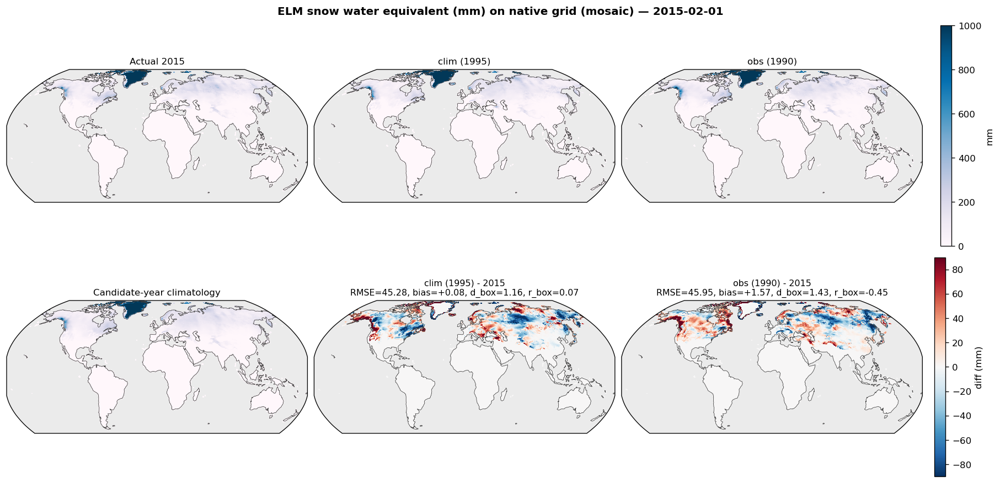

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/elm_state_diff_surface_soil_water_20150201.png


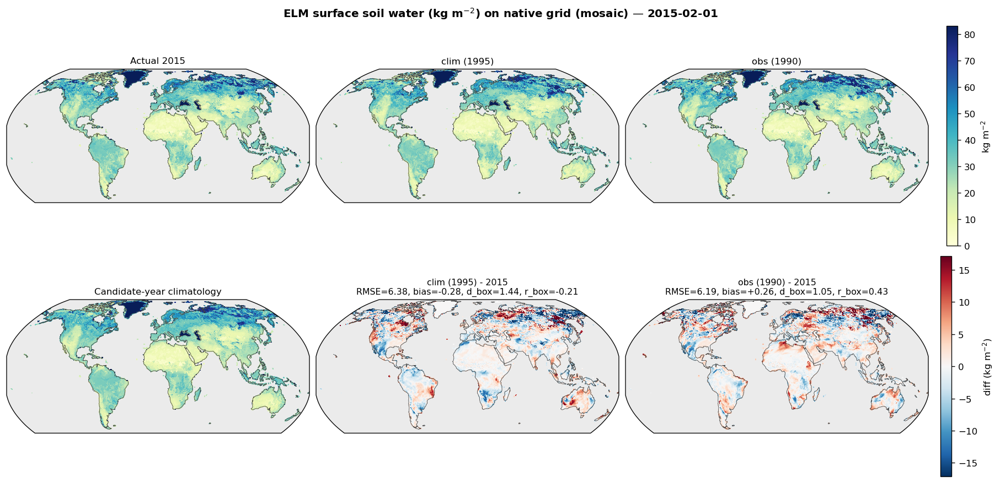

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/elm_state_diff_subsurface_soil_water_20150201.png


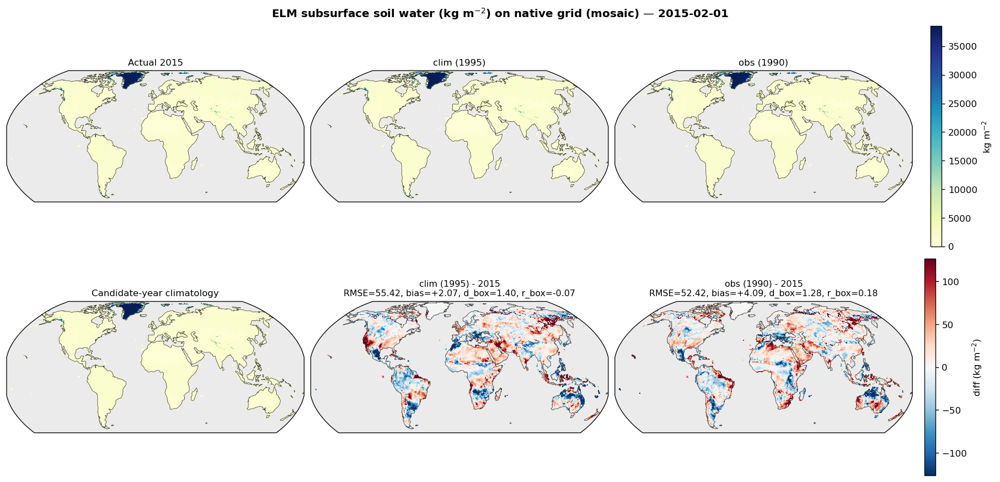

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/elm_state_diff_surface_soil_temperature_20150201.png


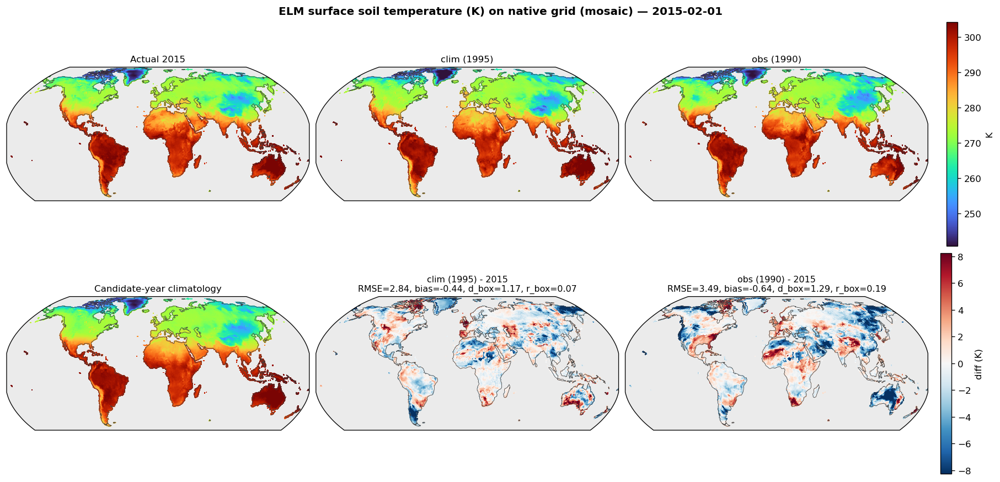

In [2]:
plan_ex = plans["clim", EXAMPLE_DATE]
byears_ex = {
    "clim": selections["clim", EXAMPLE_DATE]["elm"],
    "obs": selections["obs", EXAMPLE_DATE]["elm"],
}

elm_fields = [
    ("snow water equivalent",    "PuBu"),
    ("surface soil water",       "YlGnBu"),
    ("subsurface soil water",    "YlGnBu"),
    ("surface soil temperature", "turbo"),
]

spatial_elm = {}
for fname, cmap in elm_fields:
    sp = ice.prepare_spatial_field(
        plan_ex, "elm", fname, 2015, byears_ex, box=BOX, cache_dir=CACHE_DIR, log=lambda *_: None
    )
    spatial_elm[fname] = sp
    fig = ice.plot_elm_spatial(sp, elm_descriptor=elm_desc, kind="state_and_diff", cmap=cmap)
    ice.save_fig(
        fig, f"elm_state_diff_{ice.slugify(fname)}_{EXAMPLE_DATE.replace('-', '')}",
        DIAG_ROOT, SAVE_DIAG,
    )
    plt.show()

## 2. Standardized Anomaly ($z$) Maps on the Native ELM Mesh

Comparing `Actual 2015 (z)`, `ERA5 2015 (z)`, `obs (z)`, and `clim (z)` across all four ELM fields.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/elm_z_snow_water_equivalent_20150201.png


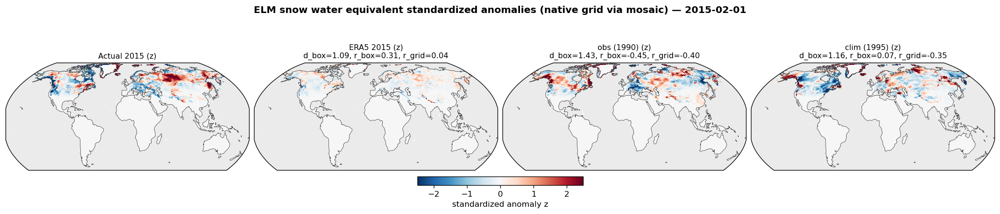

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/elm_z_surface_soil_water_20150201.png


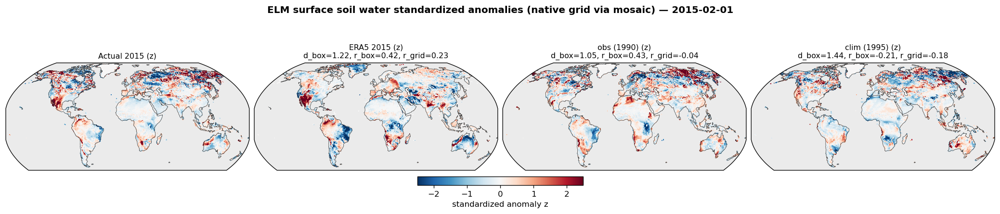

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/elm_z_subsurface_soil_water_20150201.png


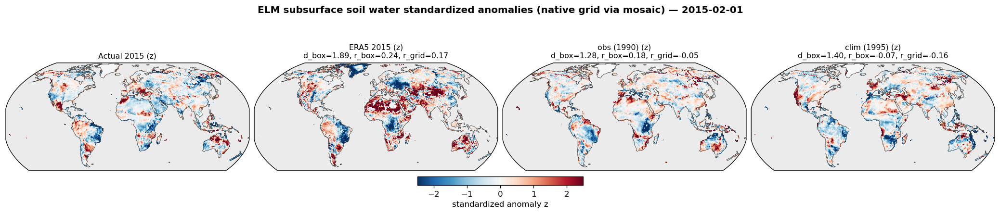

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/elm_z_surface_soil_temperature_20150201.png


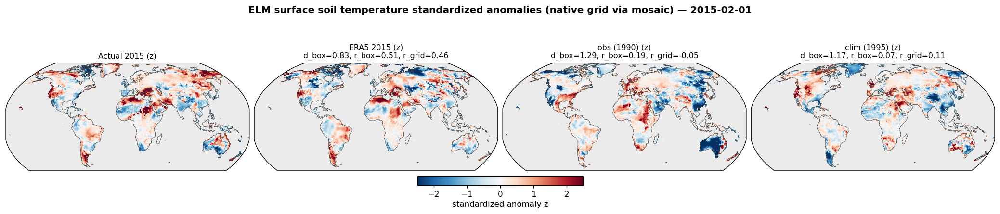

In [3]:
for fname, _ in elm_fields:
    fig = ice.plot_elm_spatial(spatial_elm[fname], elm_descriptor=elm_desc, kind="z", z_lim=2.5)
    ice.save_fig(
        fig, f"elm_z_{ice.slugify(fname)}_{EXAMPLE_DATE.replace('-', '')}",
        DIAG_ROOT, SAVE_DIAG,
    )
    plt.show()

## 3. Four-Season ELM Anomaly Comparison (`2015-02-01` to `2015-11-01`)

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/elm_4seasons_z_snow_water_equivalent_2015.png


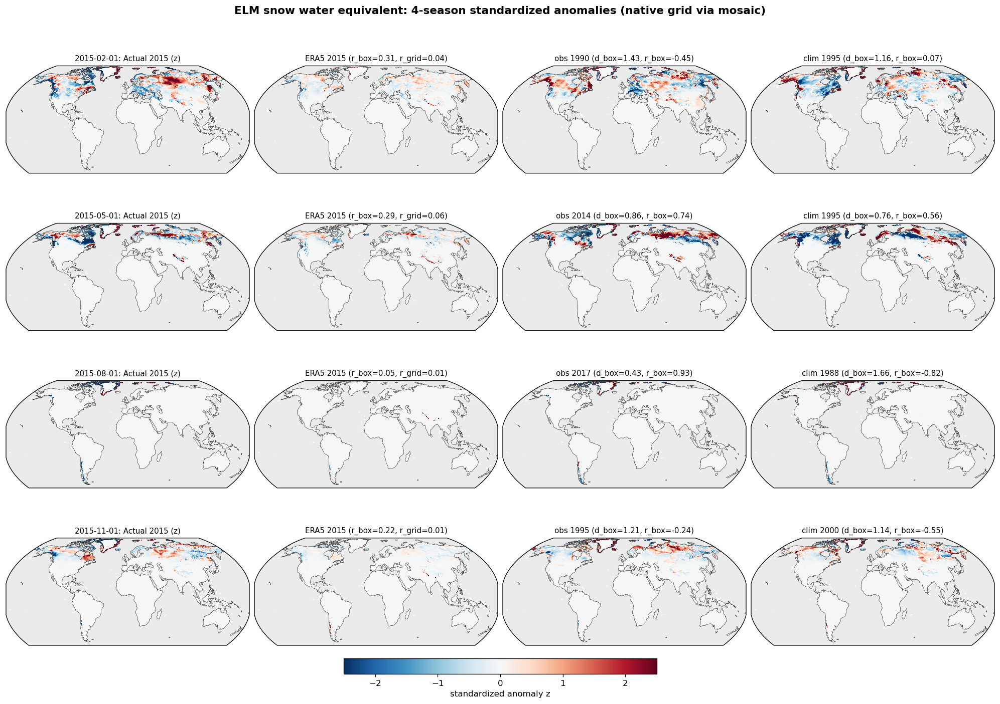

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/elm_4seasons_z_surface_soil_water_2015.png


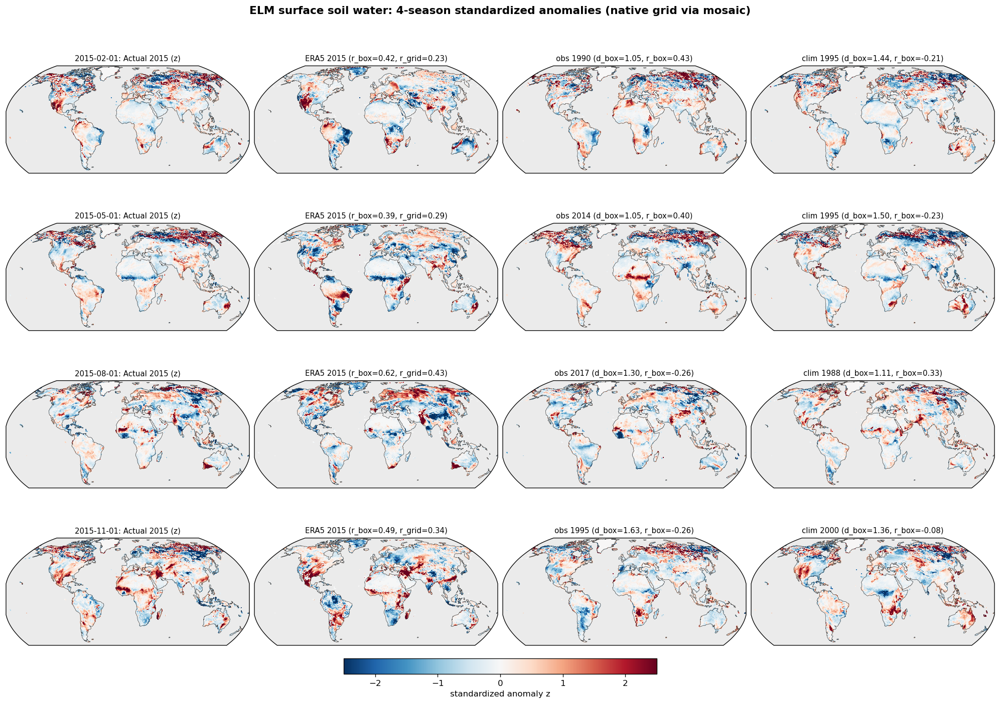

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/elm_4seasons_z_subsurface_soil_water_2015.png


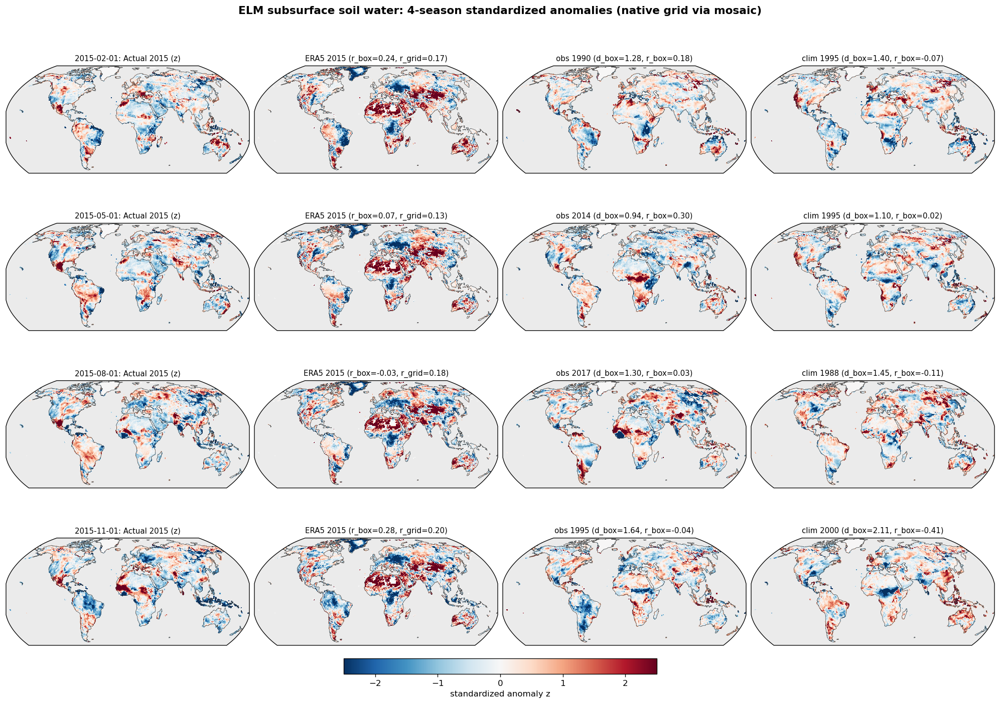

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/elm_4seasons_z_surface_soil_temperature_2015.png


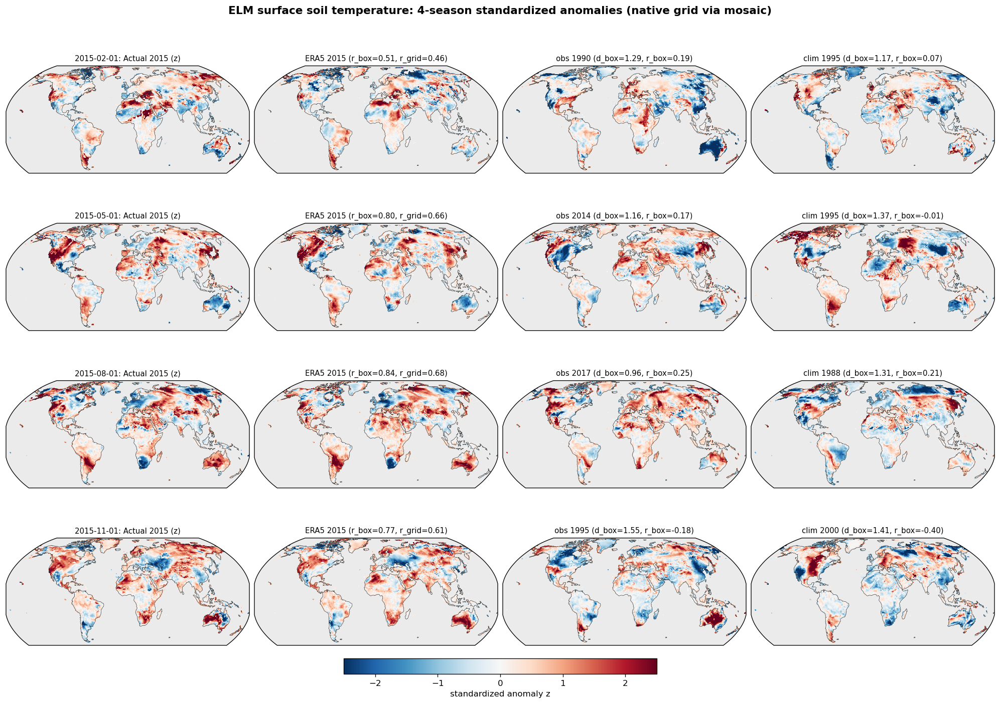

In [4]:
for fname in ["snow water equivalent", "surface soil water", "subsurface soil water", "surface soil temperature"]:
    fig = ice.plot_elm_four_seasons(
        fname, TEST_DATES, plans, selections, elm_desc,
        box=BOX, cache_dir=CACHE_DIR, z_lim=2.5,
    )
    ice.save_fig(fig, f"elm_4seasons_z_{ice.slugify(fname)}_2015", DIAG_ROOT, SAVE_DIAG)
    plt.show()